In [9]:
import pandas as pd
import csv
import matplotlib.pyplot as plt

import re 
import shutil
import numpy as np
%matplotlib inline
import subprocess
import os
import scipy.io as sio
from mpl_toolkits.axes_grid1 import AxesGrid
from collections import OrderedDict
import matplotlib.pyplot as plt
import mayavi.mlab as mlab
import copy
import time
import scipy.io as sio
import matplotlib.pyplot as plt
import numpy as np
import shdom
from shdom import float_round
fontsize = 20
from shdom.CloudCT_Utils import *
import yaml


lw = 1.5
from mpl_toolkits.axes_grid1 import AxesGrid, make_axes_locatable

In [94]:
def load_run_params(params_path):
    """
    TODO
    Args:
        params_path ():

    Returns:

    """
    # Load run parameters
    params_file_path = params_path
    with open(params_file_path, 'r') as f:
        run_params = yaml.full_load(f)
    return run_params

def calc_extinction(LWC, REFF):
    ro = 1e6 # gram/m^3
    extinction =  (3/(2*ro))*(LWC/(REFF*1e-6)) # in i/m units
    extinction = np.nan_to_num(extinction)
    return extinction*1e3 # in i/km units

In [108]:
CloudFieldFile = "/wdata_visl/generated_clouds/clouds/cloud19370.txt" 
# CloudFieldFile = "/wdata_visl/generated_clouds/clouds/cloud1954.txt" # lwc: 0.8 reff: 6.2

run_params = load_run_params(params_path="../CloudCT_scripts/run_params.yaml")
mie_options = run_params['mie_options']

mie_table_path = "/wdata_visl/generated_clouds/mie_tables/polydisperse/averaged_Water_647nm.scat"
# mie_table_path = "/wdata_visl/generated_clouds/mie_tables/polydisperse/Water_650nm.scat"
wavelength = 0.647
# wavelength = 0.65

mie = shdom.MiePolydisperse()
mie.read_table(mie_table_path)

droplets = shdom.MicrophysicalScatterer()
droplets.load_from_csv(CloudFieldFile)

lwc = droplets.lwc.data
veff = droplets.veff.data
reff = droplets.reff.data

start_veff = mie_options['start_veff']
start_reff = mie_options['start_reff']
# start_reff = 4.0
end_veff = mie_options['end_veff']
# end_veff = 0.2
end_reff = mie_options['end_reff']
veff[veff<=start_veff] = start_veff
veff[veff>=end_veff] = end_veff 

reff[reff<=start_reff] = start_reff
reff[reff>=end_reff] = end_reff 
# optical depth:
droplets.add_mie(mie) 

medium = shdom.Medium(droplets.grid)
# add a scatterer to the medium:
medium.add_scatterer(droplets, name='clouds')

cloud = medium.get_scatterer(name='clouds')
reff = cloud.reff.data
veff = cloud.veff.data
lwc = cloud.lwc.data
extinction_at_wavelength = cloud.get_extinction(wavelength=wavelength)

Reading mie table from file: /wdata_visl/generated_clouds/mie_tables/polydisperse/averaged_Water_647nm.scat


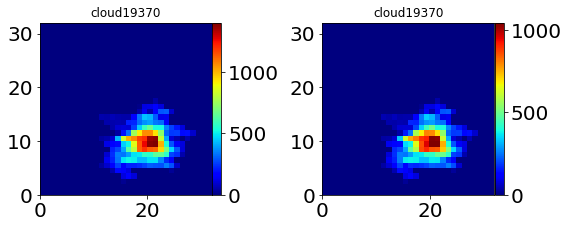

In [109]:
z = extinction_at_wavelength.grid.z
x = extinction_at_wavelength.grid.x
y = extinction_at_wavelength.grid.y
nx,ny,nz = extinction_at_wavelength.shape
X,Y,Z = np.meshgrid(x,y,z,indexing='ij')
DZ = np.diff(Z)
DZ = np.pad(DZ, ((0, 0), (0, 0), (0, 1)), 'constant', constant_values=DZ[0,0,nz-2])
optical_depth = np.sum(DZ*extinction_at_wavelength.data, axis=2)

fig,ax = plt.subplots(1,2,figsize=(8, 6))
im = ax[0].imshow(optical_depth, vmin=0, vmax=optical_depth.max(),\
                           extent=[0, optical_depth.shape[1], 0, optical_depth.shape[0]], cmap='jet')
ax[0].grid(False)
ax[0].set_title(CloudFieldFile.split('/')[-1].split('.')[0])

divider = make_axes_locatable(ax[0])
cax = divider.append_axes("right", size="5%", pad=0.01)
cbar = plt.colorbar(im, cax=cax) 

cbar.ax.tick_params(labelsize=20) 
ax[0].xaxis.set_tick_params(labelsize=20)
ax[0].yaxis.set_tick_params(labelsize=20)   

# calculate extinction with estimation:
extinction_estimated = calc_extinction(lwc, reff)
optical_depth_estimated = np.sum(DZ*extinction_estimated, axis=2)

im = ax[1].imshow(optical_depth_estimated, vmin=0, vmax=optical_depth_estimated.max(),\
                           extent=[0, optical_depth_estimated.shape[1], 0, optical_depth_estimated.shape[0]], cmap='jet')
ax[1].grid(False)
ax[1].set_title(CloudFieldFile.split('/')[-1].split('.')[0])

divider = make_axes_locatable(ax[1])
cax = divider.append_axes("right", size="5%", pad=0.01)
cbar = plt.colorbar(im, cax=cax) 

cbar.ax.tick_params(labelsize=20) 
ax[1].xaxis.set_tick_params(labelsize=20)
ax[1].yaxis.set_tick_params(labelsize=20)    

plt.tight_layout()


In [33]:
reff.shape

(35, 28, 54)

cloud26760.txt
/wdata_visl/generated_clouds/original_clouds_w_txt/cloud26760.txt


/home/vhold/miniconda3/envs/pyshdom/lib/python3.7/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide


cloud27120.txt
/wdata_visl/generated_clouds/original_clouds_w_txt/cloud27120.txt


/home/vhold/miniconda3/envs/pyshdom/lib/python3.7/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide


cloud14940.txt
/wdata_visl/generated_clouds/original_clouds_w_txt/cloud14940.txt


/home/vhold/miniconda3/envs/pyshdom/lib/python3.7/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide
/home/vhold/miniconda3/envs/pyshdom/lib/python3.7/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide


... (3 outputs left out)

/home/vhold/miniconda3/envs/pyshdom/lib/python3.7/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide
/home/vhold/miniconda3/envs/pyshdom/lib/python3.7/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide


cloud11100.txt
/wdata_visl/generated_clouds/original_clouds_w_txt/cloud11100.txt
cloud10740.txt
/wdata_visl/generated_clouds/original_clouds_w_txt/cloud10740.txt


/home/vhold/miniconda3/envs/pyshdom/lib/python3.7/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide
/home/vhold/miniconda3/envs/pyshdom/lib/python3.7/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide


cloud18300.txt
/wdata_visl/generated_clouds/original_clouds_w_txt/cloud18300.txt


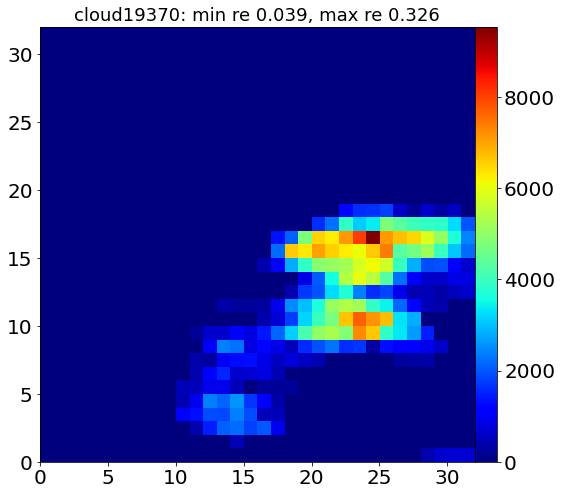

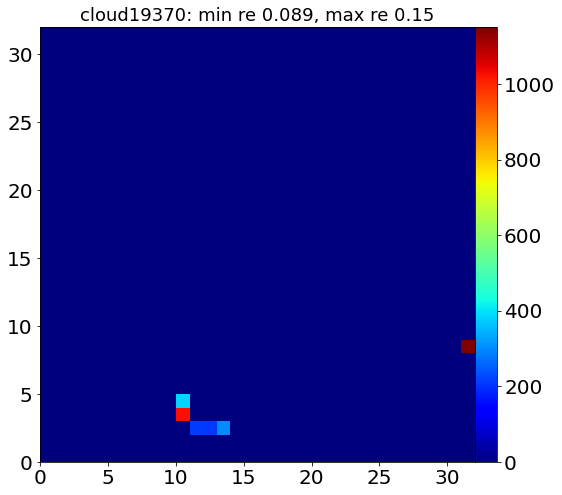

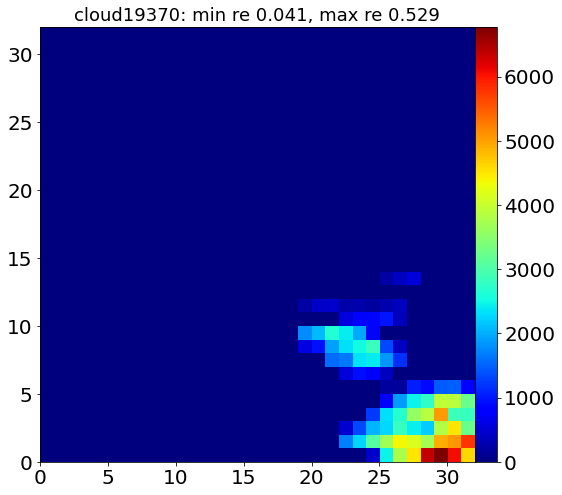

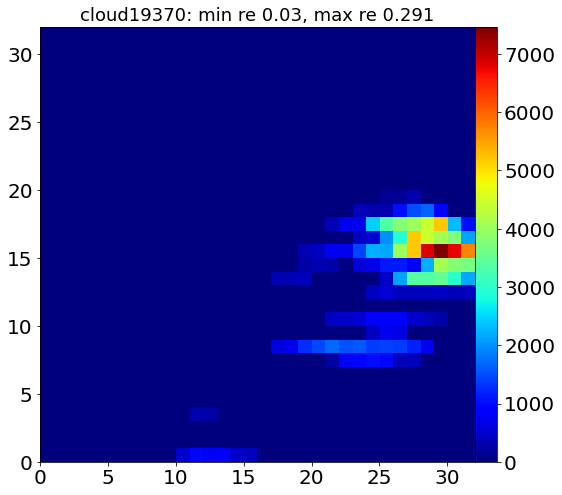

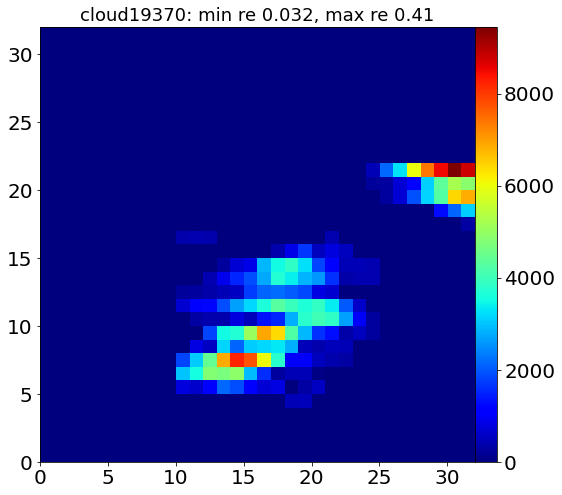

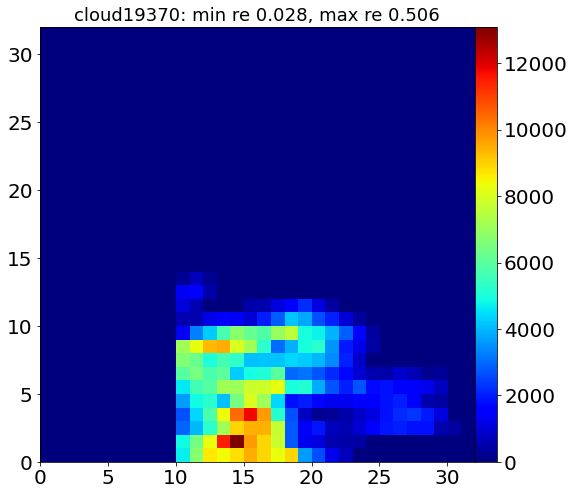

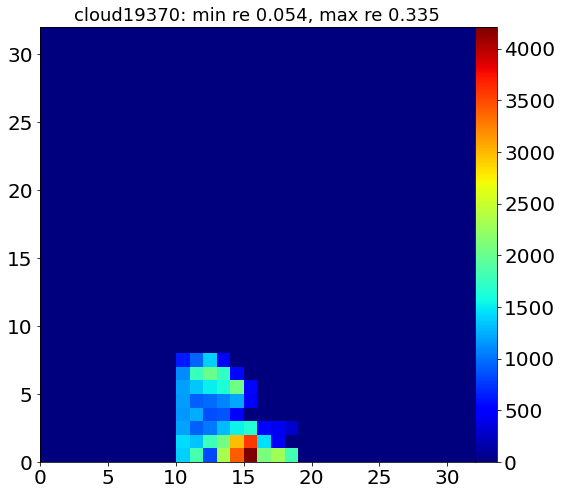

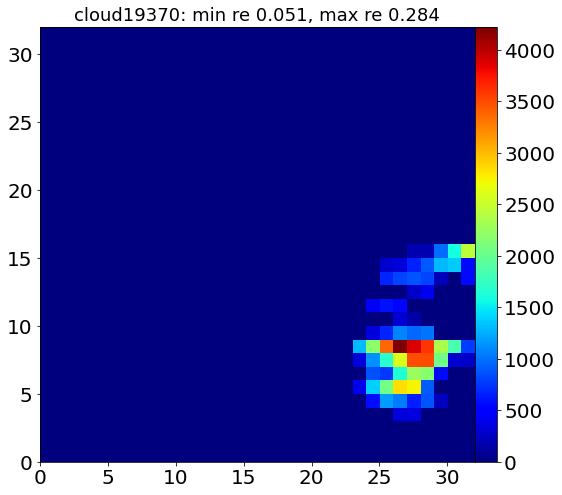

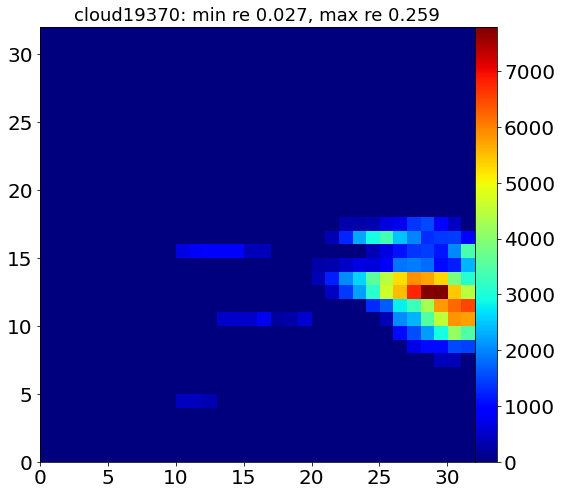

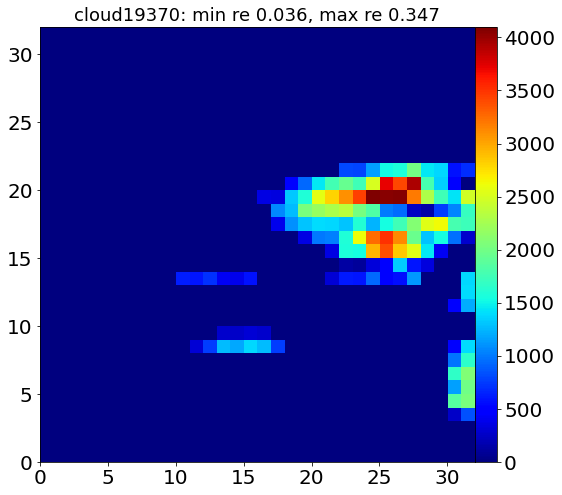

In [110]:
ref_path = "/wdata_visl/generated_clouds/original_clouds_w_txt"
# ref_path = "/wdata/roironen/Data/BOMEX_256x256x100_5000CCN_50m_micro_256/clouds/"
# ref_path = "/wdata_visl/vhold/CloudCT_153/pyshdom_153/synthetic_cloud_fields/yael_to_show/"
# ref_path = "/wdata_visl/NEW_BOMEX/processed_BOMEX_256x256x100_5000CCN_50m/"

USE_MAT = False

fh = 0
for filename in os.listdir(ref_path):
    if USE_MAT:
        formater = ".mat"
    else:
        formater = ".txt"
        
    
    if filename.endswith(".txt"):
        print(filename)
        filepath = os.path.join(ref_path, filename)
        print(filepath)
        
        droplets = shdom.MicrophysicalScatterer()
        if USE_MAT:
            DATA_DICT = sio.loadmat(filepath)
            lwc = DATA_DICT['lwc']
            veff = DATA_DICT['veff']
            reff = DATA_DICT['reff']

            grid_x = DATA_DICT['x']
            grid_z = DATA_DICT['z']
            grid_y = DATA_DICT['y']

            x_max = int((DATA_DICT['x'][0][-1]/0.05) + 1)
            y_max = int((DATA_DICT['y'][0][-1]/0.05) + 1)
            z_max = int((DATA_DICT['z'][0][-1]/0.04) + 1)

            bounding_box = shdom.BoundingBox(0,
                                         0,
                                         0,
                                         x_max,
                                         y_max,
                                         z_max)

            grid = shdom.Grid(bounding_box=bounding_box,\
                              nx=grid_x.size,
                          ny=grid_y.size,
                          nz=grid_z.size)
            
        else:
            droplets.load_from_csv(filepath)
            lwc = droplets.lwc.data
            reff = droplets.reff.data
        
        
        min_reff = reff[reff>0].min()
        max_reff = reff[reff>0].max()
        
        extinction_estimated = calc_extinction(lwc, reff)
        optical_depth_estimated = np.sum(0.04*extinction_estimated, axis=2)
        
#         lwc = shdom.GridData(grid,lwc)
#         veff = shdom.GridData(grid,veff)
#         reff = shdom.GridData(grid,reff)
        
        
        if 0:
            droplets = shdom.MicrophysicalScatterer(lwc=lwc,reff=reff,veff=veff)

            start_veff = mie_options['start_veff']
            start_reff = mie_options['start_reff']
            end_veff = mie_options['end_veff']
            end_reff = mie_options['end_reff']
    #         veff[veff<=start_veff] = start_veff
    #         veff[veff>=end_veff] = end_veff 

    #         reff[reff<=start_reff] = start_reff
    #         reff[reff>=end_reff] = end_reff 
            # optical depth:
            droplets.add_mie(mie) 

            medium = shdom.Medium(droplets.grid)
            # add a scatterer to the medium:
            medium.add_scatterer(droplets, name='clouds')

            cloud = medium.get_scatterer(name='clouds')
            reff = cloud.reff.data
            veff = cloud.veff.data
            lwc = cloud.lwc.data
            extinction_at_wavelength = cloud.get_extinction(wavelength=0.647)

            z = extinction_at_wavelength.grid.z
            x = extinction_at_wavelength.grid.x
            y = extinction_at_wavelength.grid.y
            nx,ny,nz = extinction_at_wavelength.shape
            X,Y,Z = np.meshgrid(x,y,z,indexing='ij')
            DZ = np.diff(Z)
            DZ = np.pad(DZ, ((0, 0), (0, 0), (0, 1)), 'constant', constant_values=DZ[0,0,nz-2])
            optical_depth = np.sum(DZ*extinction_at_wavelength.data, axis=2)

        f, ax = plt.subplots(1, 1, figsize=(12, 8))
        im = ax.imshow(optical_depth_estimated, vmin=0, vmax=optical_depth_estimated.max(),\
                                   extent=[0, optical_depth_estimated.shape[1], 0, optical_depth_estimated.shape[0]], cmap='jet')
        ax.grid(False)
        ax.set_title(CloudFieldFile.split('/')[-1].split('.')[0]+": min re {}, max re {}".format(min_reff,max_reff), fontsize=18)

        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.01)
        cbar = plt.colorbar(im, cax=cax) 

        cbar.ax.tick_params(labelsize=20) 
        ax.xaxis.set_tick_params(labelsize=20)
        ax.yaxis.set_tick_params(labelsize=20) 
        fh += 1
        
        if(fh ==10 ):
            break

In [92]:
reff.max()

15.244095

In [93]:
reff[reff>0].min()

2.3434117

In [71]:
DATA_DICT['x'].shape

(1, 256)

256.0


In [89]:
reff.data

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.